# 03 · Validación integrada: tracking + equipos + roles sobre coordenadas de campo

**Objetivo:** validar el pipeline completo sobre un vídeo independiente, resolviendo además el rol de cada identidad (jugador, portero, árbitro, fuera de campo) mediante coordenadas de campo obtenidas por homografía.

**Diseño:** la clasificación de equipos es un problema de color (modelo equipación-césped). El rol es un problema de semántica espacial, irresoluble en píxeles (portero y juez de línea son indistinguibles en imagen) y trivial en metros: quien se proyecta fuera del rectángulo del campo es asistente/staff; el outlier de color anclado junto a una portería es el portero (equipo por voto de proximidad); el outlier móvil dentro del campo es el árbitro.

**Salidas:** vídeo anotado con equipos y roles, precisión de clasificación sobre m uestra manual, y JSON con posiciones de campo (interfaz de la fase 5).

**Importante:** reiniciar el kernel antes de ejecutar (estado del tracker).vale con esto que has hecho te cargas al arbtro de campo(lo asigna como jugador del equpo de blanco y negro) pero si que pone bien al portero del lado izquierod pero no el del derecho. Creo que todos estos problemas se solucionarian si se creara otro dataset mucho mas amplio autoetiquetado con el existente para crear un modelo de deteccion de jugadores mas preciso

In [1]:
import json
import cv2
import numpy as np
from pathlib import Path
from collections import defaultdict, deque
from ultralytics import YOLO

REPO_ROOT = Path("../..").resolve()

# ===== PARÁMETRO =====
VIDEO_IN = REPO_ROOT / "data" / "raw" / "A1606b0e6_0 (62).mp4"# =====================

NOMBRE = VIDEO_IN.stem.replace(" ", "_").replace("(", "").replace(")", "")
detector = YOLO(str(REPO_ROOT / "models" / "best_v4.pt"))
kp_model = YOLO(str(REPO_ROOT / "models" / "keypoints_base.pt"))

tracker_cfg = REPO_ROOT / "configs" / "botsort_custom.yaml"
tracker_cfg.parent.mkdir(parents=True, exist_ok=True)
if not tracker_cfg.exists():
    tracker_cfg.write_text("""tracker_type: botsort
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.6
track_buffer: 120
match_thresh: 0.8
fuse_score: true
gmc_method: sparseOptFlow
proximity_thresh: 0.5
appearance_thresh: 0.25
with_reid: true
model: auto
""", encoding="utf-8")

KP_REALES = np.array([
    (0,0),(0,68),(105,0),(105,68),(16.5,13.84),(16.5,54.16),(88.5,13.84),(88.5,54.16),
    (5.5,24.84),(5.5,43.16),(99.5,24.84),(99.5,43.16),(11,34),(94,34),(52.5,34),
    (52.5,0),(52.5,68),(0,13.84),(0,54.16),(105,13.84),
    (0,30.34),(0,37.66),(105,30.34),(105,37.66)], dtype=np.float32)
EXCLUIR_KP = {14, 15, 16}
PORTERIAS = np.array([[0.0, 34.0], [105.0, 34.0]])

print(f"Vídeo existe: {VIDEO_IN.exists()} | Nombre: {NOMBRE}")

Vídeo existe: True | Nombre: A1606b0e6_0_62


In [2]:
# ---- 1. Tracking + división por clase + cosido + filtro de espurios (pipeline de fase 4) ----
frames_dets = []
results = detector.track(source=str(VIDEO_IN), stream=True, persist=True,
                         tracker=str(tracker_cfg), conf=0.25, imgsz=1280, verbose=False)
for n, rd in enumerate(results):
    dets = []
    if rd.boxes is not None and rd.boxes.id is not None:
        for (x1, y1, x2, y2), tid, c in zip(rd.boxes.xyxy.cpu().numpy(),
                                            rd.boxes.id.cpu().numpy().astype(int),
                                            rd.boxes.cls.cpu().numpy().astype(int)):
            dets.append((int(tid), float(x1), float(y1), float(x2), float(y2), int(c)))
    frames_dets.append(dets)
    if (n + 1) % 100 == 0:
        print(f"Tracking: {n + 1} frames...")
N_FRAMES = len(frames_dets)

tracks_full = defaultdict(list)
for f_idx, dets in enumerate(frames_dets):
    for (tid, x1, y1, x2, y2, c) in dets:
        tracks_full[tid].append((f_idx, (x1 + x2) / 2, y2, int(c)))

MIN_SEG = 15
tracks2, clase2, mapa_det = {}, {}, {}
next_id = 1
for tid, pts in tracks_full.items():
    segs, actual, pendiente, c_actual = [], [], [], None
    for p in pts:
        c = p[3]
        if c_actual is None:
            c_actual = c
        if c == c_actual:
            if pendiente:
                actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente]); pendiente = []
            actual.append(p)
        else:
            pendiente.append(p)
            if len(pendiente) >= MIN_SEG:
                if actual:
                    segs.append((c_actual, actual))
                c_actual, actual, pendiente = c, [(f, x, y, c) for (f, x, y, _) in pendiente], []
    if pendiente:
        actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente])
    if actual:
        segs.append((c_actual, actual))
    for c_seg, seg in segs:
        nid = next_id; next_id += 1
        tracks2[nid] = [(f, x, y) for (f, x, y, c) in seg]
        clase2[nid] = c_seg
        for (f, x, y, c) in seg:
            mapa_det[(f, tid)] = nid

MAX_GAP, MAX_SOLAPE, RADIO_BASE, RADIO_POR_FRAME, RADIO_SOLAPE = 75, 12, 50, 5, 35
resumen, pos_pf = {}, {}
for nid, pts in tracks2.items():
    if clase2[nid] not in (1, 2) or len(pts) < 3:
        continue
    arr = np.array(pts); ult = arr[-5:]
    dt = ult[-1, 0] - ult[0, 0]
    vel = (ult[-1, 1:] - ult[0, 1:]) / dt if dt > 0 else np.zeros(2)
    resumen[nid] = {"ini": int(arr[0, 0]), "fin": int(arr[-1, 0]),
                    "pos_ini": arr[0, 1:], "pos_fin": arr[-1, 1:], "vel": vel}
    pos_pf[nid] = {int(f): np.array([x, y]) for f, x, y in pts}

cands = []
for ta, ra in resumen.items():
    for tb, rb in resumen.items():
        if ta == tb or clase2[ta] != clase2[tb]:
            continue
        gap = rb["ini"] - ra["fin"]
        if gap > MAX_GAP or gap < -MAX_SOLAPE:
            continue
        if gap > 0:
            d = np.linalg.norm(rb["pos_ini"] - (ra["pos_fin"] + ra["vel"] * gap))
            r = RADIO_BASE + RADIO_POR_FRAME * gap
        else:
            pa = pos_pf[ta].get(rb["ini"])
            if pa is None:
                continue
            d, r = np.linalg.norm(rb["pos_ini"] - pa), RADIO_SOLAPE
        if d <= r:
            cands.append((d, ta, tb))
cands.sort()
uf, ui, fusion = set(), set(), {}
for d, ta, tb in cands:
    if ta in uf or tb in ui:
        continue
    fusion[tb] = ta; uf.add(ta); ui.add(tb)
def raiz(t):
    while t in fusion:
        t = fusion[t]
    return t
mapa_final = {nid: raiz(nid) for nid in resumen}

# ---- Filtro de segmentos espurios -------------------------------------------
# Un segmento es ESPURIO si dura muy pocos frames Y solapa temporalmente con otro
# segmento de su MISMA clase (tras el cosido): es una doble caja del detector, no
# una identidad. No se filtra por duración a secas (un segmento corto pero solo
# puede ser una entrada/salida real de cuadro). Diagnóstico en test (27): los
# segmentos 31/37/88/89/90 (1-2 det) solapaban con el árbitro 15 -> cajas fantasma.
MIN_DET_SEG = 5     # menos detecciones que esto = candidato a espurio

# Rango temporal e id raíz (clase) de cada segmento consolidado
rango_seg = {nid: (int(arr[0, 0]), int(arr[-1, 0]))
             for nid, pts in tracks2.items() if len(pts) > 0
             for arr in [np.array(pts)]}
raiz_de = {nid: int(mapa_final.get(nid, nid)) for nid in tracks2}

espurios = set()
for nid, pts in tracks2.items():
    if len(pts) >= MIN_DET_SEG:
        continue
    if nid not in rango_seg:
        continue
    a0, a1 = rango_seg[nid]
    cls_a = clase2[nid]
    # ¿solapa con OTRO segmento de la misma clase (raíz distinta) y más largo?
    for otro, pts2 in tracks2.items():
        if otro == nid or clase2[otro] != cls_a or len(pts2) < MIN_DET_SEG:
            continue
        if raiz_de[otro] == raiz_de[nid]:
            continue   # mismo objeto cosido: no es competencia, es continuidad
        b0, b1 = rango_seg[otro]
        if not (a1 < b0 or a0 > b1):   # hay solapamiento temporal
            espurios.add(nid)
            break

print(f"Segmentos espurios filtrados (< {MIN_DET_SEG} det y solapan con misma clase): "
      f"{len(espurios)} -> {sorted(espurios)}")

frames_track = []
for f_idx, dets in enumerate(frames_dets):
    fr = []
    for (tid, x1, y1, x2, y2, c) in dets:
        if c in (1, 2):
            nid = mapa_det.get((f_idx, tid), tid)
            if nid in espurios:           # detección de un segmento espurio: se descarta
                continue
            idf = int(mapa_final.get(nid, nid))
        else:
            idf = int(tid)
        fr.append({"id": idf, "bbox": [x1, y1, x2, y2], "cls": c})
    frames_track.append(fr)
print(f"IDs de persona tras post-procesado: "
      f"{len({d['id'] for fr in frames_track for d in fr if d['cls'] in (1, 2)})}")

Tracking: 100 frames...
Tracking: 200 frames...
Tracking: 300 frames...
Tracking: 400 frames...
Tracking: 500 frames...
Tracking: 600 frames...
Tracking: 700 frames...
Segmentos espurios filtrados (< 5 det y solapan con misma clase): 14 -> [27, 32, 36, 38, 47, 49, 52, 54, 60, 61, 62, 63, 64, 66]
IDs de persona tras post-procesado: 26


In [3]:
# ---- 1b. Detección dedicada del BALÓN (umbral bajo + enlace por proximidad) ----
# El balón se detectaba con conf ~0.576 pero new_track_thresh=0.6 de BoT-SORT lo descartaba
# (no le creaba track). Aquí se detecta directamente con conf 0.3, sin el tracker pesado:
# el balón es ÚNICO, basta enlazarlo por cercanía frame a frame y filtrar saltos imposibles.

CONF_BALON = 0.30          # captura el balón real (mediana 0.576), corta ruido (<0.15)
MAX_SALTO_BALON_PX = 250   # px entre frames: el balón no salta más de esto a 25fps (filtra falsos)

# Detectar el balón en cada frame, quedándose con el candidato de MÁS confianza
detec_balon = {}   # f_idx -> (x_centro, y_pie, conf)
cap = cv2.VideoCapture(str(VIDEO_IN))
f_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    res = detector(frame, conf=CONF_BALON, imgsz=1280, verbose=False, classes=[0])[0]
    if res.boxes is not None and len(res.boxes) > 0:
        confs = res.boxes.conf.cpu().numpy()
        boxes = res.boxes.xyxy.cpu().numpy()
        k = int(np.argmax(confs))          # el balón es único: el candidato más confiado
        x1, y1, x2, y2 = boxes[k]
        detec_balon[f_idx] = ((x1 + x2) / 2, y2, float(confs[k]))
    f_idx += 1
    if f_idx % 100 == 0:
        print(f"Balón: {f_idx} frames...")
cap.release()
print(f"Balón detectado (conf>={CONF_BALON}): {len(detec_balon)}/{N_FRAMES} = {100*len(detec_balon)/N_FRAMES:.0f}%")

# Filtrar falsos positivos por coherencia de trayectoria: un salto imposible entre dos
# detecciones consecutivas indica que una es falsa. Se marca para descartar la de MENOR
# confianza, sin modificar el diccionario mientras se recorre.
fs = sorted(detec_balon)
a_descartar = set()
for i in range(1, len(fs)):
    fa, fb = fs[i-1], fs[i]
    if fa in a_descartar:        # si ya marcamos el anterior, comparar con el previo válido
        # buscar la última detección válida antes de fb
        j = i - 1
        while j >= 0 and fs[j] in a_descartar:
            j -= 1
        if j < 0:
            continue
        fa = fs[j]
    if fb - fa > 3:              # hueco grande: no se puede juzgar el salto
        continue
    xa, ya, ca = detec_balon[fa]
    xb, yb, cb = detec_balon[fb]
    salto = np.hypot(xb - xa, yb - ya) / (fb - fa)
    if salto > MAX_SALTO_BALON_PX:
        a_descartar.add(fa if ca < cb else fb)

for f in a_descartar:
    detec_balon.pop(f, None)
print(f"Falsos positivos descartados por trayectoria: {len(a_descartar)}")
print(f"Balón final: {len(detec_balon)}/{N_FRAMES} = {100*len(detec_balon)/N_FRAMES:.0f}%")

# Inyectar el balón en frames_track, reemplazando las detecciones de balón viejas (cls=0)
# que venían del tracker (pobres). Se le da un id fijo (-100) al ser único.
ID_BALON = -100
for f_idx in range(len(frames_track)):
    # quitar balones viejos de este frame
    frames_track[f_idx] = [d for d in frames_track[f_idx] if d["cls"] != 0]
    # añadir el balón nuevo si se detectó
    if f_idx in detec_balon:
        x_c, y_pie, conf = detec_balon[f_idx]
        # bbox aproximado centrado en el pie (el balón es pequeño)
        frames_track[f_idx].append({
            "id": ID_BALON,
            "bbox": [x_c - 8, y_pie - 16, x_c + 8, y_pie],
            "cls": 0,
        })

n_balon_track = sum(1 for fr in frames_track for d in fr if d["cls"] == 0)
print(f"Balones inyectados en frames_track: {n_balon_track}")

Balón: 100 frames...
Balón: 200 frames...
Balón: 300 frames...
Balón: 400 frames...
Balón: 500 frames...
Balón: 600 frames...
Balón: 700 frames...
Balón detectado (conf>=0.3): 537/749 = 72%
Falsos positivos descartados por trayectoria: 3
Balón final: 534/749 = 71%
Balones inyectados en frames_track: 534


In [4]:
# ---- 2. Pasada de vídeo: HOMOGRAFÍAS DE PnLCalib + colores + proyección ----
# La homografía de cada frame se LEE del .npz generado por el notebook 10 (PnLCalib),
# en vez de calcularse con keypoints. PnLCalib calibra por puntos Y líneas, lo que
# resuelve los planos abiertos donde la homografía por keypoints colapsaba.

# Cargar las homografías precalculadas de PnLCalib
NOMBRE_PNL = "A1606b0e6_0_62"
PNL_NPZ = REPO_ROOT / "data" / "tracking" / f"homografias_pnl_{NOMBRE_PNL}.npz"
_pnl = np.load(PNL_NPZ)
H_PNL = _pnl["homografias"]   # (n_frames, 3, 3), NaN donde PnLCalib no calibró
print(f"Homografías PnLCalib cargadas: {H_PNL.shape}")
n_validas_pnl = sum(1 for i in range(len(H_PNL)) if not np.isnan(H_PNL[i]).any())
print(f"  Frames con homografía válida: {n_validas_pnl}/{len(H_PNL)}")

def color_camiseta(frame, bbox):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    hb, wb = y2 - y1, x2 - x1
    if hb < 10 or wb < 4:
        return None
    crop = frame[max(y1 + int(0.22 * hb), 0):y1 + int(0.50 * hb),
                 max(x1 + int(0.25 * wb), 0):x2 - int(0.25 * wb)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    pix = crop[cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) == 0].astype(np.float32)
    if len(pix) < 30:
        return None
    if len(pix) > 300:
        pix = pix[np.random.default_rng(0).choice(len(pix), 300, replace=False)]
    if len(pix) < 60:
        return pix.mean(axis=0)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, lb, ct = cv2.kmeans(pix, 3, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    return ct[np.bincount(lb.ravel()).argmax()]

colores_det = {}    # (f, id) -> (BGR, peso)   solo cls 1
campo_det = {}      # (f, id) -> (X, Y) metros  cls 0,1,2  (incluye balón)
n_con_H = n_sin_H = 0

cap = cv2.VideoCapture(str(VIDEO_IN))
for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break

    # Homografía de PnLCalib para este frame (None si no calibró)
    H_vigente = None
    if f_idx < len(H_PNL) and not np.isnan(H_PNL[f_idx]).any():
        H_vigente = H_PNL[f_idx]
        n_con_H += 1
    else:
        n_sin_H += 1

    # Proyectar pies. AHORA incluye el balón (cls 0), no solo jugadores/porteros (1,2)
    for d in dets:
        if d["cls"] not in (0, 1, 2):
            continue
        x1, y1, x2, y2 = d["bbox"]
        if H_vigente is not None:
            pie = np.array([[[(x1 + x2) / 2, y2]]], dtype=np.float32)
            X, Y = cv2.perspectiveTransform(pie, H_vigente)[0][0]
            campo_det[(f_idx, d["id"])] = (float(X), float(Y))
        if d["cls"] == 1:
            c = color_camiseta(frame, d["bbox"])
            if c is not None:
                colores_det[(f_idx, d["id"])] = (c, y2 - y1)

    if (f_idx + 1) % 100 == 0:
        print(f"Análisis: {f_idx + 1}/{N_FRAMES} frames...")
cap.release()

print(f"\nFrames con homografía PnLCalib: {n_con_H} | sin: {n_sin_H}")
print(f"Detecciones con color: {len(colores_det)} | con posición de campo: {len(campo_det)}")

# Diagnóstico: posiciones sanas
import numpy as _np
xs_chk = _np.array([v[0] for v in campo_det.values()])
print(f"Posiciones sanas (|X|<200): {(_np.abs(xs_chk)<200).sum()}/{len(xs_chk)} = {100*(_np.abs(xs_chk)<200).mean():.0f}%")

Homografías PnLCalib cargadas: (749, 3, 3)
  Frames con homografía válida: 749/749
Análisis: 100/749 frames...
Análisis: 200/749 frames...
Análisis: 300/749 frames...
Análisis: 400/749 frames...
Análisis: 500/749 frames...
Análisis: 600/749 frames...
Análisis: 700/749 frames...

Frames con homografía PnLCalib: 749 | sin: 0
Detecciones con color: 14938 | con posición de campo: 16994
Posiciones sanas (|X|<200): 16994/16994 = 100%


In [5]:
# ---- 3. Clasificación de equipos (BGR + K-means por identidad) ----
# Reescrita: el espacio Lab-ab anterior separaba mal (rojo oscuro vs blanco se distinguen
# por brillo/saturación, que ab descarta). BGR separa el doble de bien. Y se clasifica por
# IDENTIDAD (color mediano de cada jugador en todo el vídeo), no por detección suelta:
# más estable y elimina el ruido frame a frame.

def color_torso(frame, bbox):
    """Color BGR mediano del torso del jugador, filtrando el verde del césped."""
    x1, y1, x2, y2 = [int(v) for v in bbox]
    hb, wb = y2 - y1, x2 - x1
    if hb < 10 or wb < 4:
        return None
    crop = frame[max(y1 + int(0.22*hb), 0):y1 + int(0.50*hb),
                 max(x1 + int(0.25*wb), 0):x2 - int(0.25*wb)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    pix = crop[cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) == 0]
    if len(pix) < 30:
        return None
    return np.median(pix.astype(float), axis=0)   # BGR mediano

# Recoger color por IDENTIDAD a lo largo del vídeo (más estable que por detección)
col_por_id = defaultdict(list)
pos_por_id = defaultdict(list)
cap = cv2.VideoCapture(str(VIDEO_IN))
f_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    for d in frames_track[f_idx]:
        if d["cls"] != 1:          # solo jugadores de campo para aprender los 2 equipos
            continue
        c = color_torso(frame, d["bbox"])
        if c is not None:
            col_por_id[d["id"]].append(c)
            p = campo_det.get((f_idx, d["id"]))
            if p is not None:
                pos_por_id[d["id"]].append(p)
    f_idx += 1
    if f_idx % 100 == 0:
        print(f"Color por identidad: {f_idx} frames...")
cap.release()

# Color mediano de cada identidad con suficientes muestras
ids_validos = [i for i, cs in col_por_id.items() if len(cs) >= 3]
col_id = np.array([np.median(col_por_id[i], axis=0) for i in ids_validos])
print(f"Identidades con color estable: {len(ids_validos)}")

# K-means en BGR -> 2 equipos
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
_, labels_k, centers = cv2.kmeans(col_id.astype(np.float32), 2, None, crit, 20, cv2.KMEANS_PP_CENTERS)
labels_k = labels_k.ravel()

# Mapa identidad -> equipo (0/1)
equipo_de_id = {ids_validos[j]: int(labels_k[j]) for j in range(len(ids_validos))}

# Color BGR representativo de cada equipo (para la pizarra), realzado
def realzar(c):
    c = np.array(c, dtype=float)
    return tuple(int(v) for v in (c / (c.max() + 1e-6) * 255))
color_equipo_bgr = {k: realzar(centers[k]) for k in (0, 1)}

# Construir equipo_det y id_final_det (interfaz que esperan las celdas siguientes).
# Sin división por segmentos: cada identidad tiene UN equipo estable.
equipo_det, id_final_det = {}, {}
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] not in (1, 2):
            continue
        nid = d["id"]
        id_final_det[(f_idx, d["id"])] = nid
        equipo_det[(f_idx, d["id"])] = equipo_de_id.get(nid, -1)

# segmentos: una entrada por identidad (compatibilidad con la celda de roles)
nids_unicos = sorted({d["id"] for fr in frames_track for d in fr if d["cls"] in (1, 2)})
segmentos = []
for nid in nids_unicos:
    eq = equipo_de_id.get(nid, -1)
    segmentos.append({"nid": nid, "id0": nid, "eq": eq, "dmin": 0.0,
                      "f0": 0, "f1": N_FRAMES, "n": 0})

n0 = sum(1 for v in equipo_de_id.values() if v == 0)
n1 = sum(1 for v in equipo_de_id.values() if v == 1)
print(f"Equipos: A(0)={color_equipo_bgr[0]} con {n0} jugadores | "
      f"B(1)={color_equipo_bgr[1]} con {n1} jugadores")

Color por identidad: 100 frames...
Color por identidad: 200 frames...
Color por identidad: 300 frames...
Color por identidad: 400 frames...
Color por identidad: 500 frames...
Color por identidad: 600 frames...
Color por identidad: 700 frames...
Identidades con color estable: 25
Equipos: A(0)=(220, 250, 254) con 13 jugadores | B(1)=(119, 182, 254) con 12 jugadores


In [6]:
# ---- 4. Resolución de roles (adaptada a clasificación BGR por identidad) ----
# Simplificada respecto a v4.2: como la clasificación de equipos ya es limpia y por identidad,
# los roles se deciden con criterios geométricos claros:
#   - ÁRBITRO: el detector lo vio mayoritariamente como cls=2 (su clasificación es fiable).
#   - PORTERO: pegado a su portería (X<8 o X>97) y poco móvil. NO en el centro del campo.
#   - JUGADOR: el resto con equipo asignado.

PORTERIAS = np.array([[0.0, 34.0], [105.0, 34.0]])
X_AREA_PORTERO = 8.0     # un portero está a menos de 8m de su línea de fondo (X<8 o X>97)
RADIO_GK_MAX = 14.0      # y se mueve poco (radio de su nube de posiciones)
nombres = {0: "A", 1: "B", -1: "-"}

# Posiciones de campo por identidad
campo_id = defaultdict(list)
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] not in (1, 2):
            continue
        nid = d["id"]
        p = campo_det.get((f_idx, d["id"]))
        if p is not None:
            campo_id[nid].append(p)

# Estadísticas de posición por identidad
stats = {}
for nid, pts in campo_id.items():
    arr = np.array(pts)
    if len(arr) >= 5:
        med = np.median(arr, axis=0)
        stats[nid] = {"med": med,
                      "radio": np.percentile(np.linalg.norm(arr - med, axis=1), 90),
                      "d_porteria": np.linalg.norm(PORTERIAS - med, axis=1).min(),
                      "x": med[0]}

# Conteo de clase del detector por identidad (para árbitros)
cls_por_nid = defaultdict(lambda: {1: 0, 2: 0})
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] in (1, 2):
            cls_por_nid[d["id"]][d["cls"]] += 1

def dentro(p):
    return -5 <= p[0] <= 110 and -5 <= p[1] <= 73

# Decidir rol de cada identidad
rol_de, equipo_seg = {}, {}
for nid in sorted({d["id"] for fr in frames_track for d in fr if d["cls"] in (1, 2)}):
    eq = equipo_de_id.get(nid, -1)
    equipo_seg[nid] = eq
    c = cls_por_nid[nid]
    total_cls = c[1] + c[2]
    st = stats.get(nid)

    # ÁRBITRO: el detector lo vio mayoritariamente como cls=2
    if total_cls > 0 and c[2] / total_cls >= 0.5:
        rol_de[nid] = "arbitro"
        equipo_seg[nid] = -1
        continue

    # Sin posición fiable: jugador si tiene equipo, si no fuera
    if st is None:
        rol_de[nid] = "jugador" if eq in (0, 1) else "fuera"
        continue

    # Fuera del campo: descartar
    if not dentro(st["med"]):
        rol_de[nid] = "fuera"
        continue

    # PORTERO: pegado a una línea de fondo (X<8 o X>97) Y poco móvil
    pegado_porteria = st["x"] < X_AREA_PORTERO or st["x"] > (105 - X_AREA_PORTERO)
    if pegado_porteria and st["radio"] <= RADIO_GK_MAX:
        rol_de[nid] = "portero"
        continue

    # JUGADOR: el resto con equipo
    rol_de[nid] = "jugador" if eq in (0, 1) else "fuera"

# Resumen
print(f"{'ID':>6} {'Rol':>9} {'Eq':>4} {'PosMed':>16} {'d_port':>8}")
for nid in sorted(stats, key=lambda n: stats[n]['x']):
    st = stats[nid]
    pos = f"({st['med'][0]:6.1f},{st['med'][1]:5.1f})"
    print(f"{nid:>6} {rol_de.get(nid,'?'):>9} {nombres.get(equipo_seg.get(nid),'-'):>4} {pos:>16} {st['d_porteria']:>7.1f}")

n_roles = defaultdict(int)
for r in rol_de.values():
    n_roles[r] += 1
print(f"\nRoles: {dict(n_roles)}")

# ---- Corrección del equipo del PORTERO: cercanía (principal) + color invertido (refuerzo) ----
# El portero viste un color distinto a ambos equipos (para diferenciarse). Por eso:
#  1) CRITERIO PRINCIPAL: cercanía. Sus defensas (su equipo) juegan cerca de él.
#  2) REFUERZO: si su color SÍ coincide claramente con un equipo, es señal de que es del OTRO
#     (un portero no viste como sus compañeros). Solo se usa si la cercanía no es concluyente.

def color_torso_id(nid):
    """Color BGR mediano del portero a lo largo del vídeo."""
    cols = []
    cap = cv2.VideoCapture(str(VIDEO_IN))
    f_idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if f_idx % 5 == 0:
            for d in frames_track[f_idx]:
                if d["id"] == nid:
                    c = color_torso(frame, d["bbox"]) if 'color_torso' in dir() else None
                    if c is not None:
                        cols.append(c)
        f_idx += 1
    cap.release()
    return np.median(cols, axis=0) if cols else None

for nid in list(rol_de.keys()):
    if rol_de.get(nid) != "portero":
        continue
    gk_pos = {}
    for f_idx, dets in enumerate(frames_track):
        for d in dets:
            if d["id"] == nid:
                p = campo_det.get((f_idx, d["id"]))
                if p is not None:
                    gk_pos[f_idx] = p
    # (1) Cercanía a compañeros
    votos = {0: 0.0, 1: 0.0}
    for f_idx, gp in gk_pos.items():
        cercanos = []
        for d in frames_track[f_idx]:
            if d["cls"] != 1 or rol_de.get(d["id"]) != "jugador":
                continue
            eq_otro = equipo_seg.get(d["id"])
            p = campo_det.get((f_idx, d["id"]))
            if eq_otro in (0, 1) and p is not None:
                cercanos.append((np.hypot(p[0]-gp[0], p[1]-gp[1]), eq_otro))
        cercanos.sort()
        for dist, eq_otro in cercanos[:3]:
            votos[eq_otro] += 1.0 / (dist + 1.0)

    total = votos[0] + votos[1]
    if total == 0:
        continue
    margen = abs(votos[0] - votos[1]) / total
    eq_cercania = 0 if votos[0] > votos[1] else 1

    # (2) Refuerzo por color SOLO si la cercanía está empatada (margen < 15%)
    eq_final = eq_cercania
    if margen < 0.15:
        gk_col = color_torso_id(nid)
        if gk_col is not None:
            c0 = np.array(color_equipo_bgr[0], dtype=float)
            c1 = np.array(color_equipo_bgr[1], dtype=float)
            d0, d1 = np.linalg.norm(gk_col - c0), np.linalg.norm(gk_col - c1)
            UMBRAL_COINCIDE = 60   # el color del portero coincide claramente con un equipo
            if min(d0, d1) < UMBRAL_COINCIDE:
                # coincide con un equipo -> es del OTRO
                eq_final = 1 if d0 < d1 else 0
                print(f"PORTERO {nid}: cercanía empatada, color coincide con equipo "
                      f"{'A' if d0<d1 else 'B'} -> asignado al OTRO ({nombres[eq_final]})")

    if equipo_seg.get(nid) != eq_final:
        print(f"PORTERO {nid}: corregido equipo {nombres.get(equipo_seg.get(nid),'-')} "
              f"-> {nombres[eq_final]} (cercanía {votos[0]:.1f} vs {votos[1]:.1f}, margen {margen*100:.0f}%)")
        equipo_seg[nid] = eq_final
        for (f, i), n in id_final_det.items():
            if n == nid:
                equipo_det[(f, i)] = eq_final

n_roles = defaultdict(int)
for r in rol_de.values():
    n_roles[r] += 1
print(f"Roles (tras corrección portero): {dict(n_roles)}")

    ID       Rol   Eq           PosMed   d_port
    23   portero    B   (   2.5, 35.3)     2.8
    27   jugador    A   (  13.9, 40.5)    15.3
    21   jugador    A   (  22.9, 21.7)    26.0
    20   arbitro    -   (  23.0,  0.7)    40.5
    13   jugador    B   (  25.0, 47.1)    28.2
    26   jugador    B   (  25.3, 35.3)    25.3
    25   jugador    A   (  25.4, 36.1)    25.5
     7   jugador    A   (  25.6, 46.7)    28.6
    30   jugador    A   (  25.6, 29.2)    26.1
    57   jugador    A   (  25.8, 54.1)    32.8
    18   jugador    B   (  26.2, 17.1)    31.2
    19   jugador    A   (  27.7, 30.9)    27.8
    24   jugador    B   (  28.7, 29.8)    29.0
    11   jugador    B   (  29.8, 14.0)    35.8
     2   jugador    B   (  31.7, 33.5)    31.7
    59   jugador    A   (  32.9, 46.6)    35.2
    16   jugador    A   (  33.0, 32.2)    33.0
    12   arbitro    -   (  33.6, 40.0)    34.1
    15   jugador    A   (  33.8, 43.9)    35.2
    29   jugador    A   (  35.1, 19.1)    38.1
    10   jug

In [7]:
# ---- 5. Vídeo anotado (output de visualización) ----
OUTPUT_EQ = REPO_ROOT / "outputs" / f"validacion_integrada_v5{NOMBRE}.mp4"
cap = cv2.VideoCapture(str(VIDEO_IN))
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter(str(OUTPUT_EQ), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        x1, y1, x2, y2 = [int(v) for v in d["bbox"]]
        if d["cls"] == 0:
            color, etiqueta = (0, 255, 255), ""
        elif d["cls"] == 2:
            color, etiqueta = (0, 0, 0), "ARB"
        else:
            nid = id_final_det.get((f_idx, d["id"]))
            rol = rol_de.get(nid, "jugador")
            eq = equipo_seg.get(nid, equipo_det.get((f_idx, d["id"])))
            if rol == "fuera":
                continue   # staff y jueces de línea: no se dibujan
            elif rol == "arbitro":
                color, etiqueta = (0, 0, 0), "ARB"
            elif rol == "portero" and eq in (0, 1):
                color, etiqueta = color_equipo_bgr[eq], "GK"
            elif eq in (0, 1):
                color, etiqueta = color_equipo_bgr[eq], ""
            else:
                color, etiqueta = (255, 0, 255), "?"
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        if etiqueta:
            cv2.putText(frame, etiqueta, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    writer.write(frame)
cap.release(); writer.release()
print(f"Vídeo guardado en: {OUTPUT_EQ}")

Vídeo guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\validacion_integrada_v5A1606b0e6_0_62.mp4


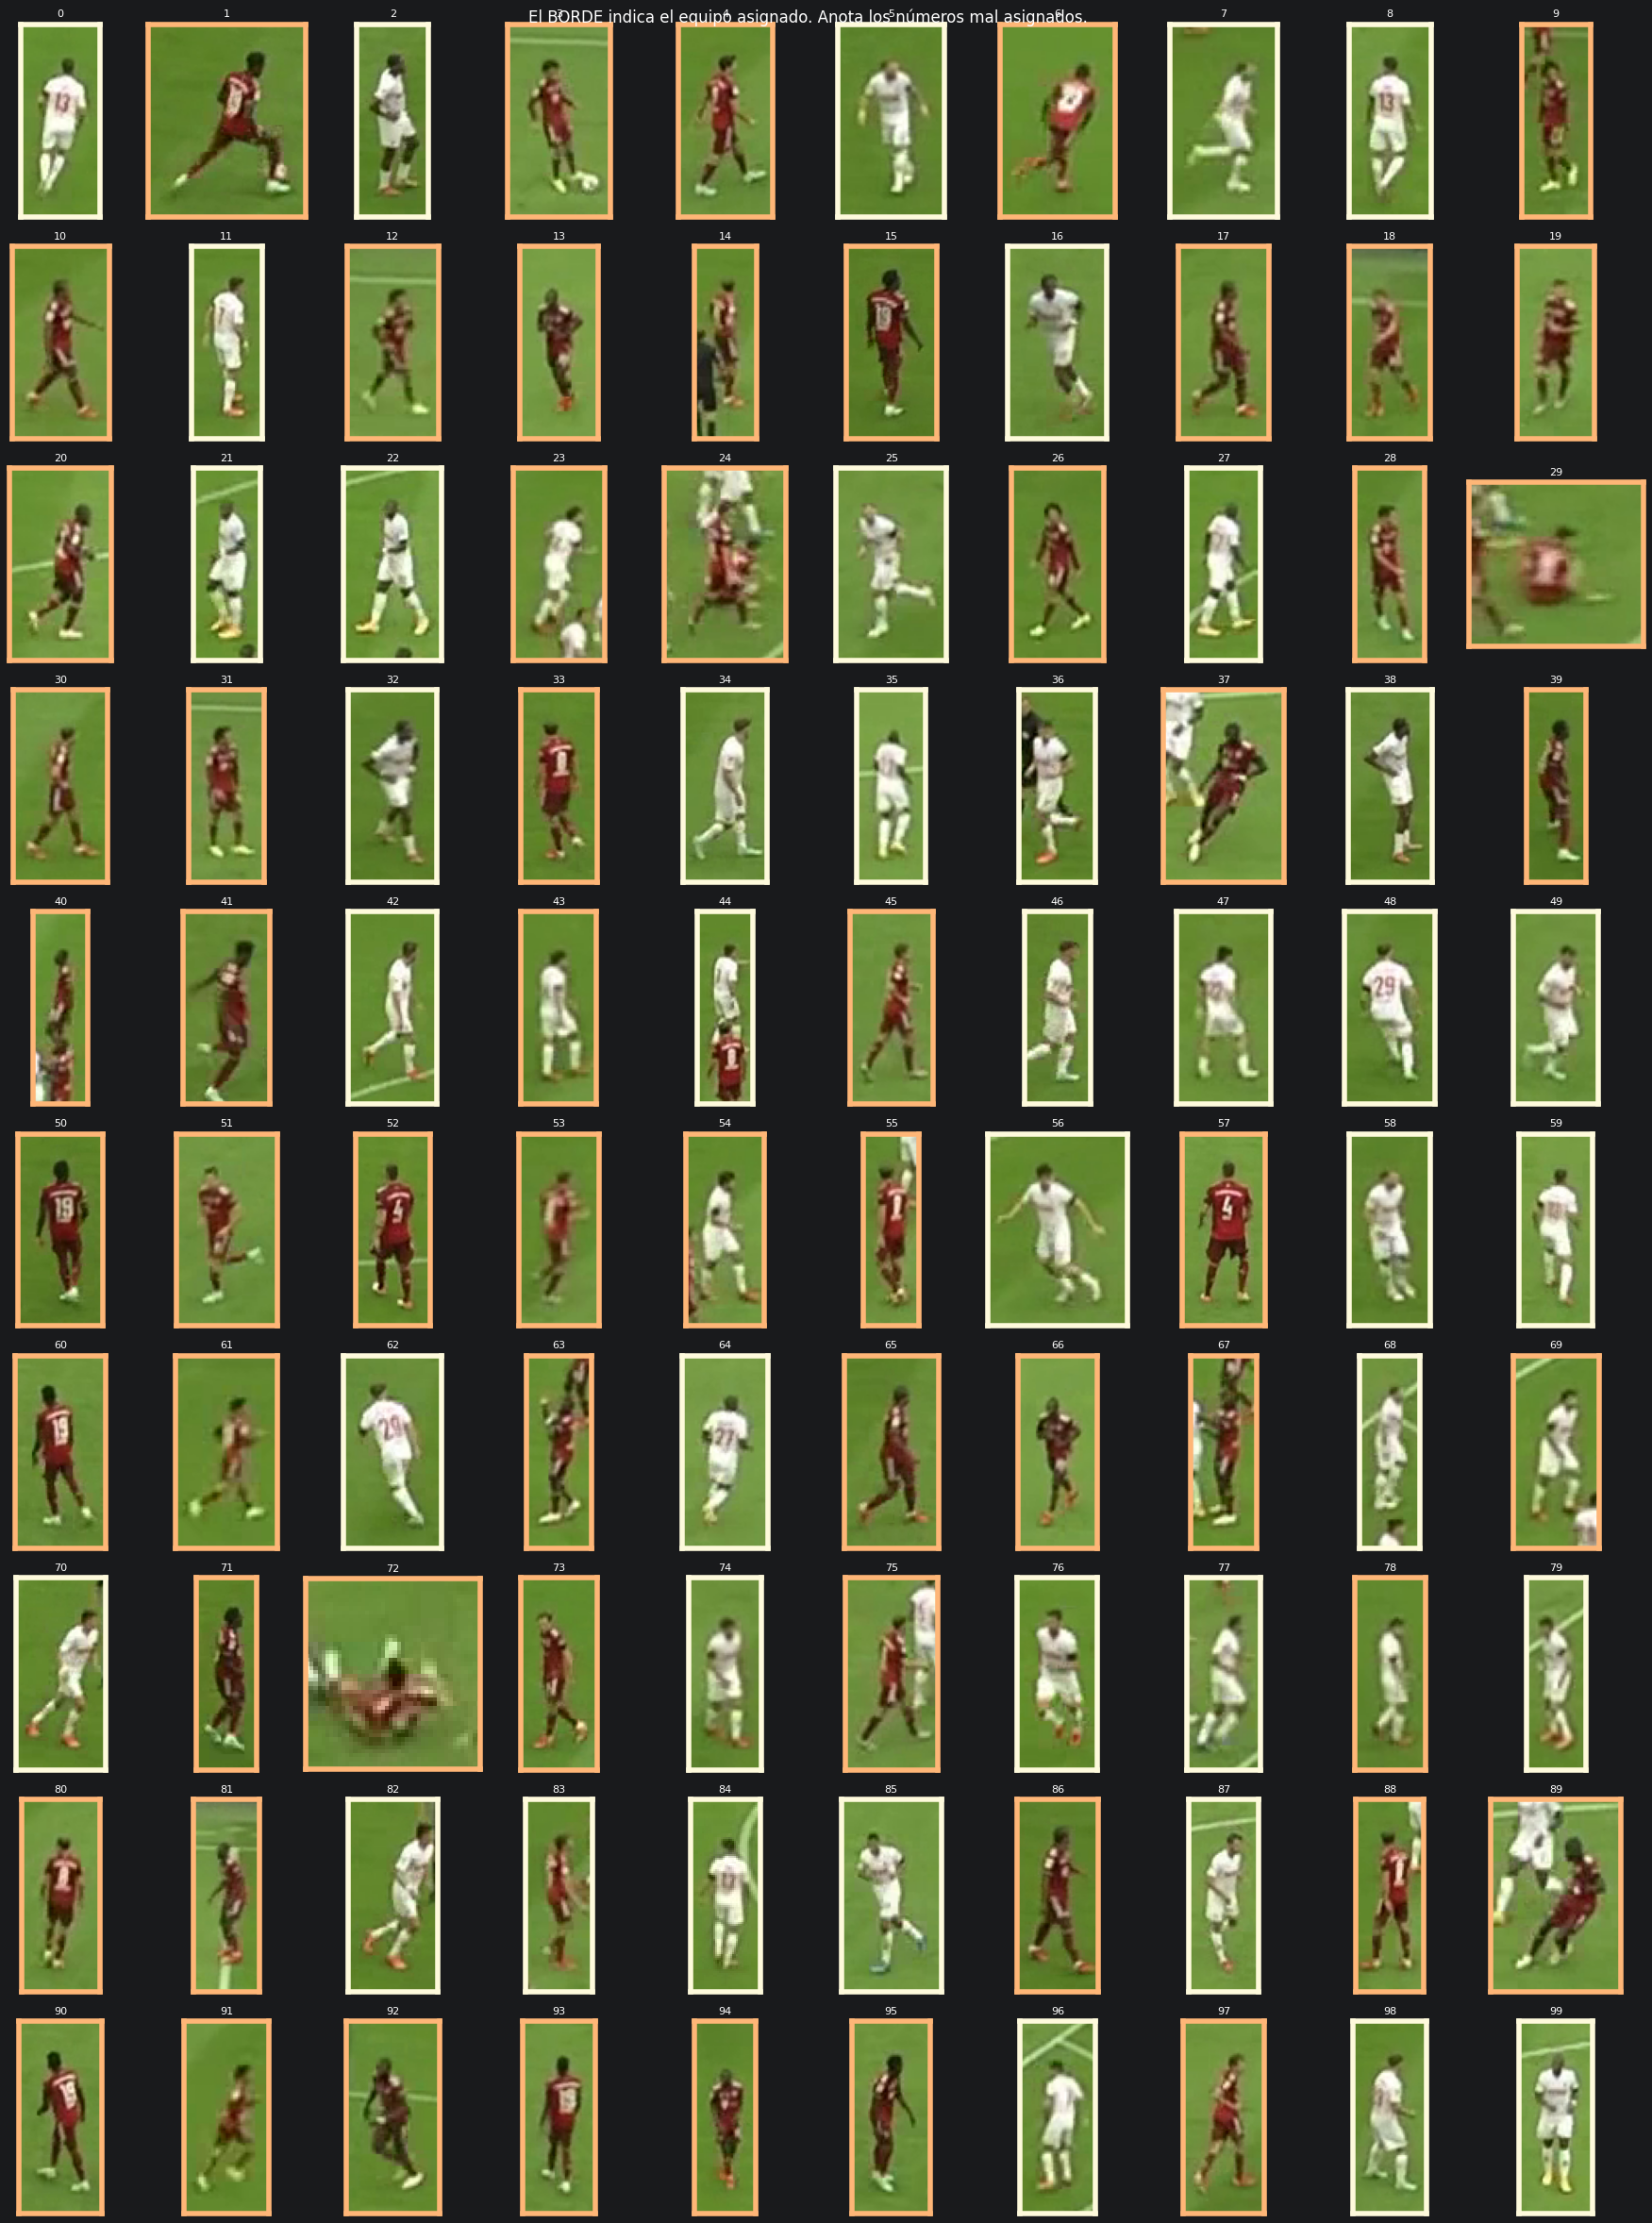

In [8]:
# ---- 6. Muestra de validación manual (solo jugadores de campo) ----
%matplotlib inline
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
candidatas = []
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] != 1:
            continue
        nid = id_final_det.get((f_idx, d["id"]))
        if rol_de.get(nid) == "jugador" and equipo_det.get((f_idx, d["id"])) in (0, 1):
            candidatas.append((f_idx, d["id"], d["bbox"], equipo_det[(f_idx, d["id"])]))

idxs = rng.choice(len(candidatas), min(100, len(candidatas)), replace=False)
muestra = [candidatas[i] for i in idxs]
imgs = {}
cap = cv2.VideoCapture(str(VIDEO_IN))
for f in sorted({m[0] for m in muestra}):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f)
    ret, fr = cap.read()
    if ret:
        imgs[f] = fr
cap.release()

cols = 10
rows = (len(muestra) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(18, 2.4 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for k, (f, tid, bbox, eq) in enumerate(muestra):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    mx, my = int(0.15 * (x2 - x1)) + 3, int(0.1 * (y2 - y1)) + 3
    crop = imgs[f][max(y1 - my, 0):y2 + my, max(x1 - mx, 0):x2 + mx]
    ax = np.ravel(axes)[k]
    if crop.size > 0:
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    b, g, r = np.array(color_equipo_bgr[eq]) / 255.0
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color((r, g, b)); sp.set_linewidth(4)
    ax.set_xticks([]); ax.set_yticks([]); ax.axis("on"); ax.set_title(f"{k}", fontsize=8)
plt.suptitle("El BORDE indica el equipo asignado. Anota los números mal asignados.")
plt.tight_layout()
plt.savefig(str(REPO_ROOT / "outputs" / f"validacion_muestra_{NOMBRE}.png"), dpi=110, bbox_inches="tight")
plt.show()

In [10]:
# ---- 7. Export del JSON integrado (interfaz de entrada de la fase 5) ----
import json

NOMBRE = VIDEO_IN.stem.replace(" ", "_").replace("(", "").replace(")", "")
OUT_JSON = REPO_ROOT / "data" / "tracking" / f"integrado_{NOMBRE}.json"
OUT_JSON.parent.mkdir(parents=True, exist_ok=True)

frames_json = []
for f_idx, dets in enumerate(frames_track):
    fr = []
    for d in dets:
        cls = d["cls"]
        item = {"id": int(d["id"]), "bbox": [float(v) for v in d["bbox"]], "cls": int(cls)}
        if cls in (1, 2):
            nid = id_final_det.get((f_idx, d["id"]))
            rol = rol_de.get(nid, "jugador" if cls == 1 else "arbitro")
            eq = equipo_seg.get(nid, equipo_det.get((f_idx, d["id"]), -1))
            if rol == "fuera":
                continue
            item["rol"] = rol
            item["equipo"] = int(eq) if eq in (0, 1) else -1
            p = campo_det.get((f_idx, d["id"]))
            item["campo"] = [float(p[0]), float(p[1])] if p is not None else None
        else:
            # BALÓN (cls 0): ahora SÍ se proyecta (la celda 2 lo incluye en campo_det)
            item["rol"] = "balon"
            item["equipo"] = -1
            p = campo_det.get((f_idx, d["id"]))
            item["campo"] = [float(p[0]), float(p[1])] if p is not None else None
        fr.append(item)
    frames_json.append(fr)

payload = {
    "video": VIDEO_IN.name,
    "n_frames": len(frames_track),
    "color_equipo_bgr": {str(k): [int(v) for v in val] for k, val in color_equipo_bgr.items()},
    "frames": frames_json,
}
with open(OUT_JSON, "w", encoding="utf-8") as fh:
    json.dump(payload, fh, ensure_ascii=False)

# Diagnóstico
import numpy as np
xs = [d["campo"][0] for fr in frames_json for d in fr
      if d.get("rol") in ("jugador", "portero") and d.get("campo")]
ys = [d["campo"][1] for fr in frames_json for d in fr
      if d.get("rol") in ("jugador", "portero") and d.get("campo")]
xs, ys = np.array(xs), np.array(ys)
n_jug = sum(1 for fr in frames_json for d in fr if d.get("rol") == "jugador")
n_gk = sum(1 for fr in frames_json for d in fr if d.get("rol") == "portero")
n_arb = sum(1 for fr in frames_json for d in fr if d.get("rol") == "arbitro")
n_balon = sum(1 for fr in frames_json for d in fr if d.get("rol") == "balon")
n_balon_campo = sum(1 for fr in frames_json for d in fr if d.get("rol") == "balon" and d.get("campo"))
print(f"JSON integrado guardado en: {OUT_JSON}")
print(f"Detecciones -> jugador: {n_jug} | portero: {n_gk} | arbitro: {n_arb} | balón: {n_balon} ({n_balon_campo} con campo)")
if len(xs):
    # Usar percentiles (robustos), no min/max que se disparan con algún outlier
    p5x, p95x = np.percentile(xs, 5), np.percentile(xs, 95)
    p5y, p95y = np.percentile(ys, 5), np.percentile(ys, 95)
    print(f"\n=== DISPERSIÓN (campo 105x68 m, percentiles 5-95) ===")
    print(f"X: p5={p5x:.0f} p95={p95x:.0f} -> ancho {p95x-p5x:.0f} m")
    print(f"Y: p5={p5y:.0f} p95={p95y:.0f} -> alto {p95y-p5y:.0f} m")
    explosivas = (np.abs(xs) > 200).sum()
    print(f"Posiciones explosivas (|X|>200): {explosivas}/{len(xs)}")

JSON integrado guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\tracking\integrado_A1606b0e6_0_62.json
Detecciones -> jugador: 14845 | portero: 144 | arbitro: 1514 | balón: 534 (534 con campo)

=== DISPERSIÓN (campo 105x68 m, percentiles 5-95) ===
X: p5=14 p95=52 -> ancho 39 m
Y: p5=11 p95=51 -> alto 40 m
Posiciones explosivas (|X|>200): 0/14989
